### Random Forests and Photo-zs

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [2]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [3]:
#!pip install astropy
import astropy

from astropy.io import fits


#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [5]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
    df = pd.DataFrame(data[1].data) 
    #https://numpy.org/doc/2.1/user/byteswapping.html 

In [6]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [7]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,,,11001673,1101,000,2003-05-06,52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"bext, bcol, possible OII",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,GALAXY,,11001699,1100,7,2003-05-03,52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,,-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,GALAXY,,11001770,1101,003,2003-05-06,52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,,-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,GALAXY,,11001800,1100,004,2003-05-03,52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,,-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,GALAXY,,11001860,1101,10,2003-05-06,52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,,-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [8]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [11]:
# Definimos la lista de filtros de interés con su sufijo
feature_cols = [f'{band}_apercor' for band in ['u', 'g', 'r', 'i', 'z', 'y']]

# Seleccionamos las características y la variable objetivo
X = df[feature_cols]

print("Features shape (X):", X.shape)
print("\nPrimeras filas de X:")
print(X.head())

Features shape (X): (23822, 6)

Primeras filas de X:
   u_apercor  g_apercor  r_apercor  i_apercor  z_apercor  y_apercor
0  23.543491  23.430495  23.100311  22.768970  22.223810  21.926356
1  30.848978  28.989668  19.027422  99.000000  99.000000  18.811085
2  24.324670  24.273606  24.150319  23.446252  23.574236 -99.000000
3  99.000000  24.804309  23.636544  23.009222  22.689591  22.535600
4  24.362068  24.136913  23.490342  22.777181  22.319676  22.100980


In [13]:
target = df['zhelio']

print("Target shape (y):", y.shape)
print(target.head())

Target shape (y): (23822,)
0    1.115261
1    0.290608
2    0.605744
3    1.306796
4    0.957669
Name: zhelio, dtype: float32


### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction](https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA)

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [14]:
model = RandomForestRegressor()

In [15]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [ ]:
%%time
# Se define la validación cruzada KFold (por ejemplo K=5)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Se ejecuta cross_validate devolviendo también los scores de train
scores = cross_validate(
    model,
    X,
    y,
    cv=kf,
    return_train_score=True,
    n_jobs=4
)

CPU times: user 73.8 ms, sys: 25.7 ms, total: 99.6 ms
Wall time: 18.9 s


In [17]:
scores

{'fit_time': array([14.67584634, 15.2460835 , 14.76165581, 16.43510103, 13.31085253]),
 'score_time': array([0.20055604, 0.15875936, 0.20427227, 0.17764974, 0.20694113]),
 'test_score': array([0.33949708, 0.3011318 , 0.29085928, 0.31653502, 0.30260003]),
 'train_score': array([0.87775747, 0.87617209, 0.87456046, 0.87522313, 0.87454579])}

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [19]:
print(f"R^2 Train promedio y desviación estándar: {scores['train_score'].mean():.4f} y {scores['train_score'].std():.4f}")
print(f"R^2 Test promedio y desviación estándar:  {scores['test_score'].mean():.4f} y {scores['test_score'].std():.4f}")

R^2 Train promedio y desviación estándar: 0.8758 y 0.0013
R^2 Test promedio y desviación estándar:  0.3117 y 0.0195


**Qué puede decir de este resultado? Hay bias alto o varianza alta?**

**RESPUESTA**: El modelo presenta una varianza meadianamente alta, lo que se traduce en una sobreajuste. 

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [21]:
ypred = cross_val_predict(model,
    X,
    y,
    cv=kf)

(0.0, 3.0)

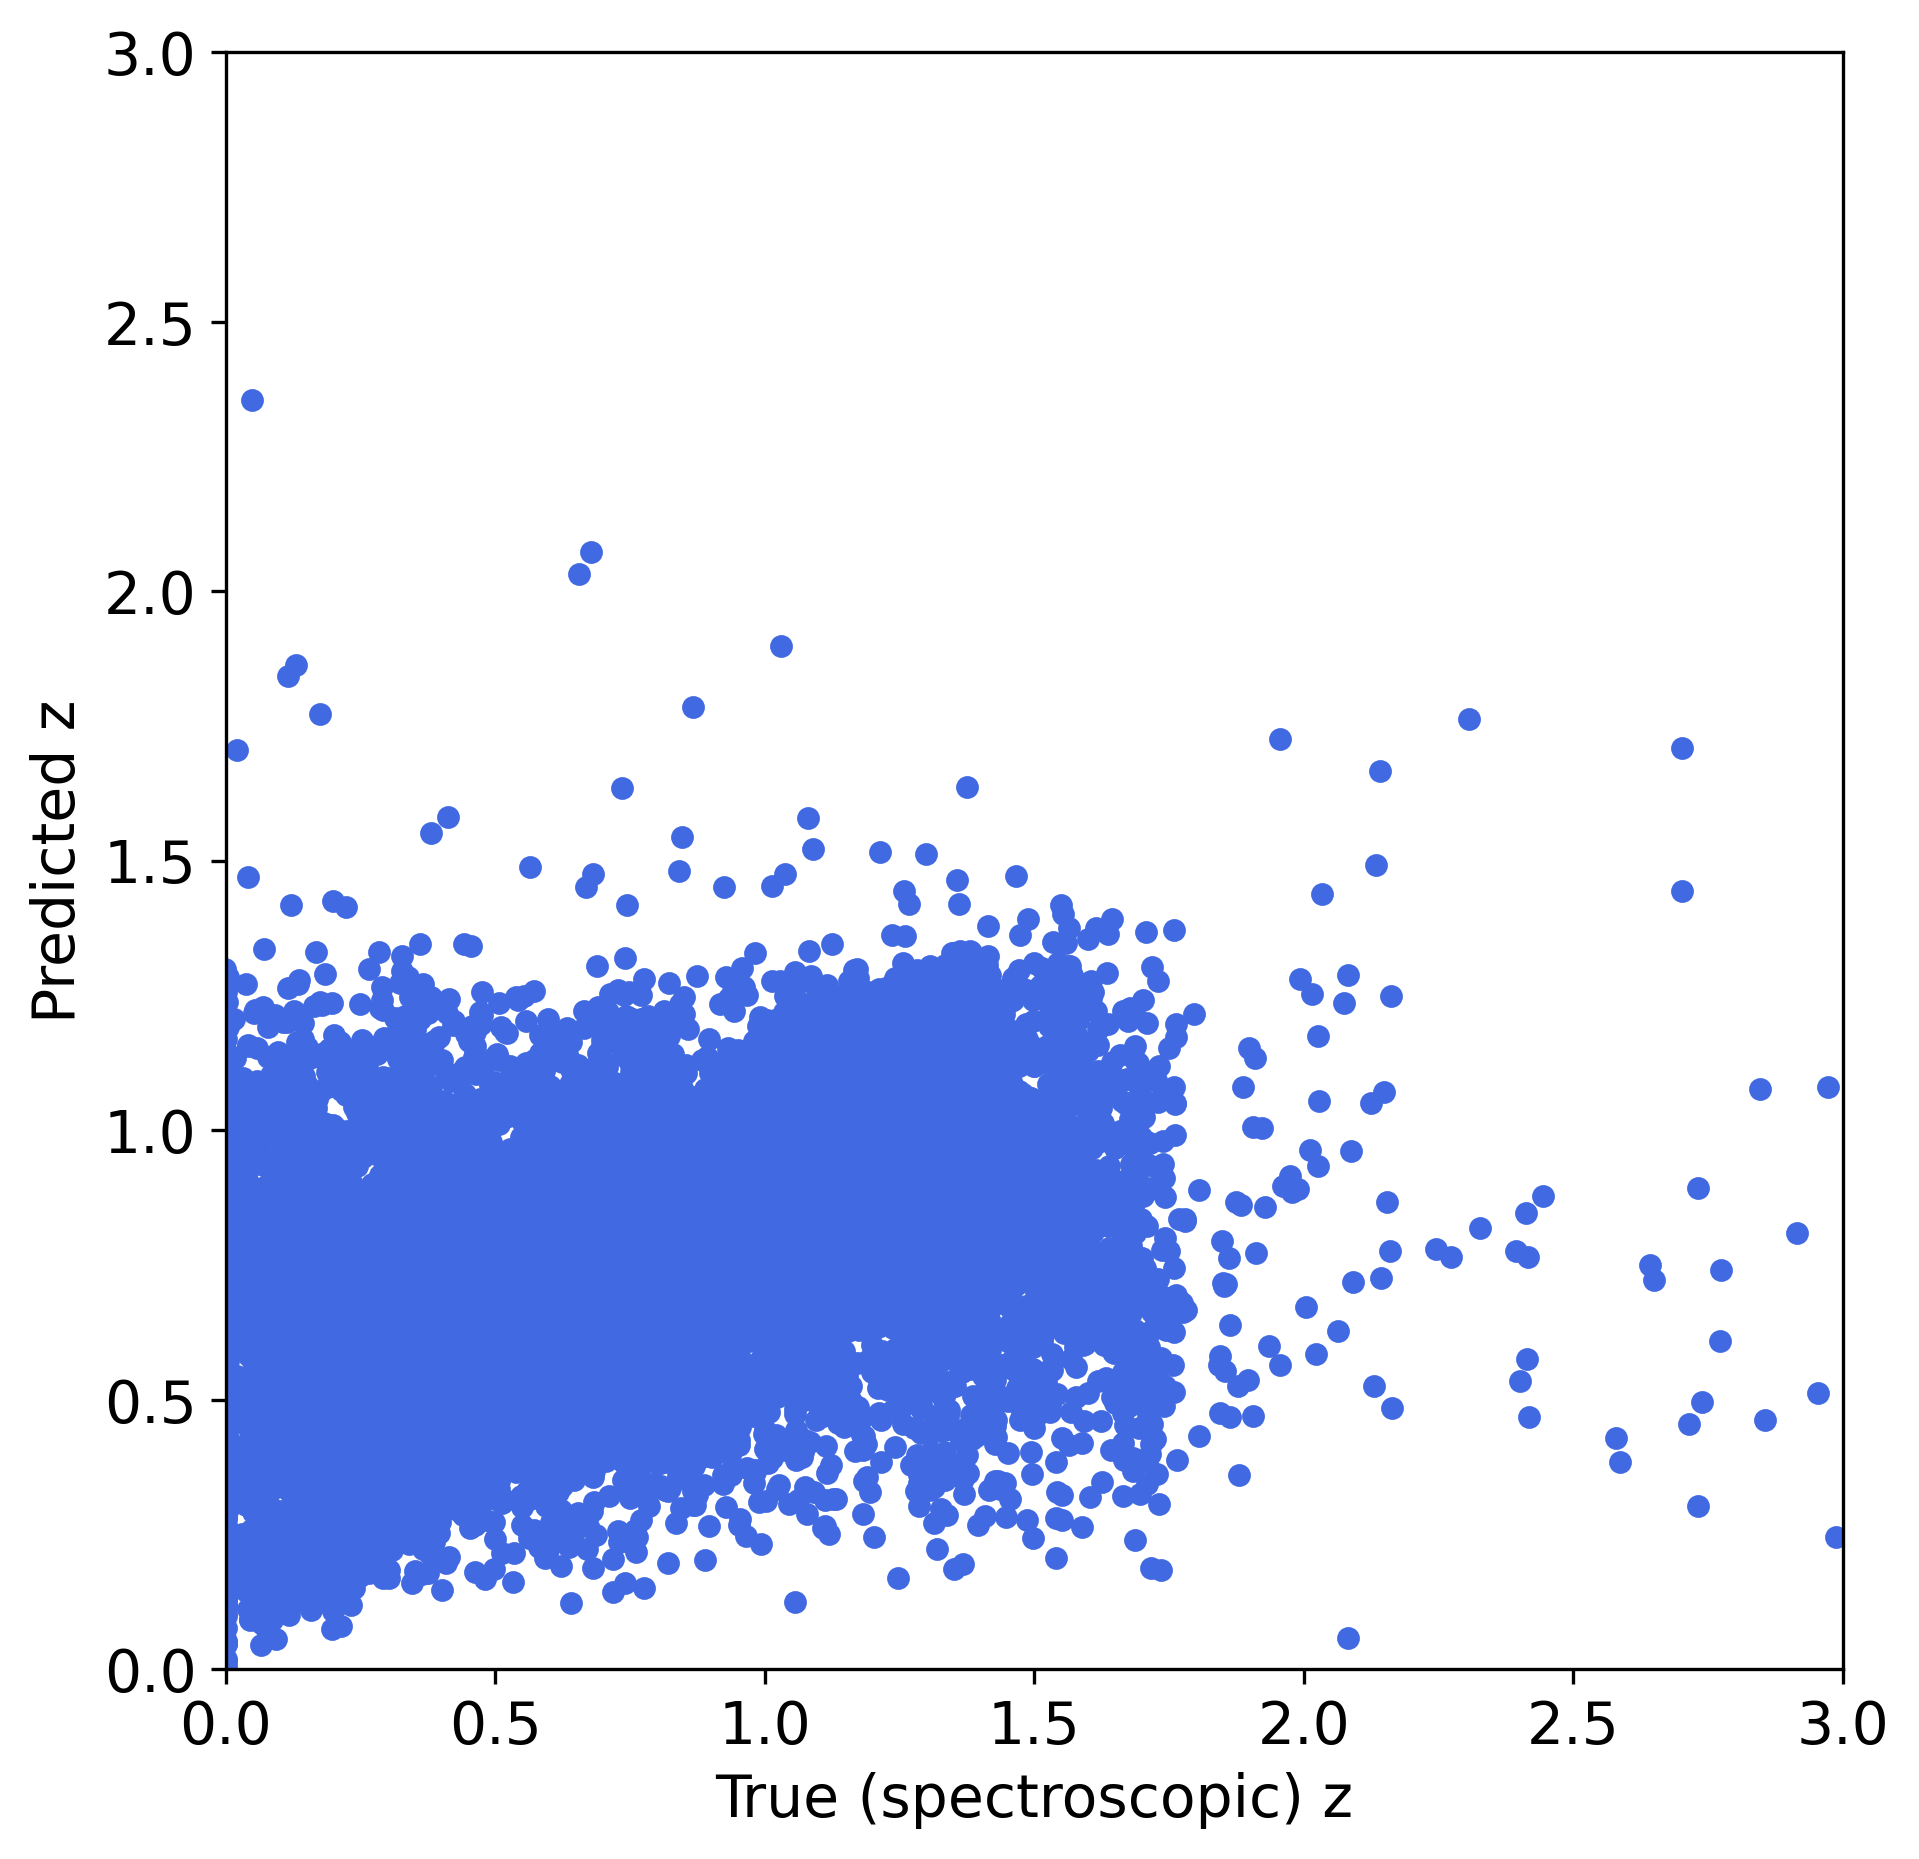

In [27]:
plt.figure(figsize=(7,7))
plt.scatter(target,ypred, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??

**RESPUESTA:** No se parece al resultado del paper, el paper maneja una relacion practicamente de 1 a 1 (lineal). El modelo base actual está prediciendo valores casi constantes en torno al promedio del dataset ($z \approx 0.4 - 0.9$), sin poder diferenciar galaxias con $z > 1.5$ ni afinar bien las de $z < 0.3$. 
Como vimos en el $R^2$ de prueba ($0.3117$ vs. $0.8758$ en entrenamiento), el Random Forest sin regularizar memorizó el set de entrenamiento y no generalizó bien.

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha. 

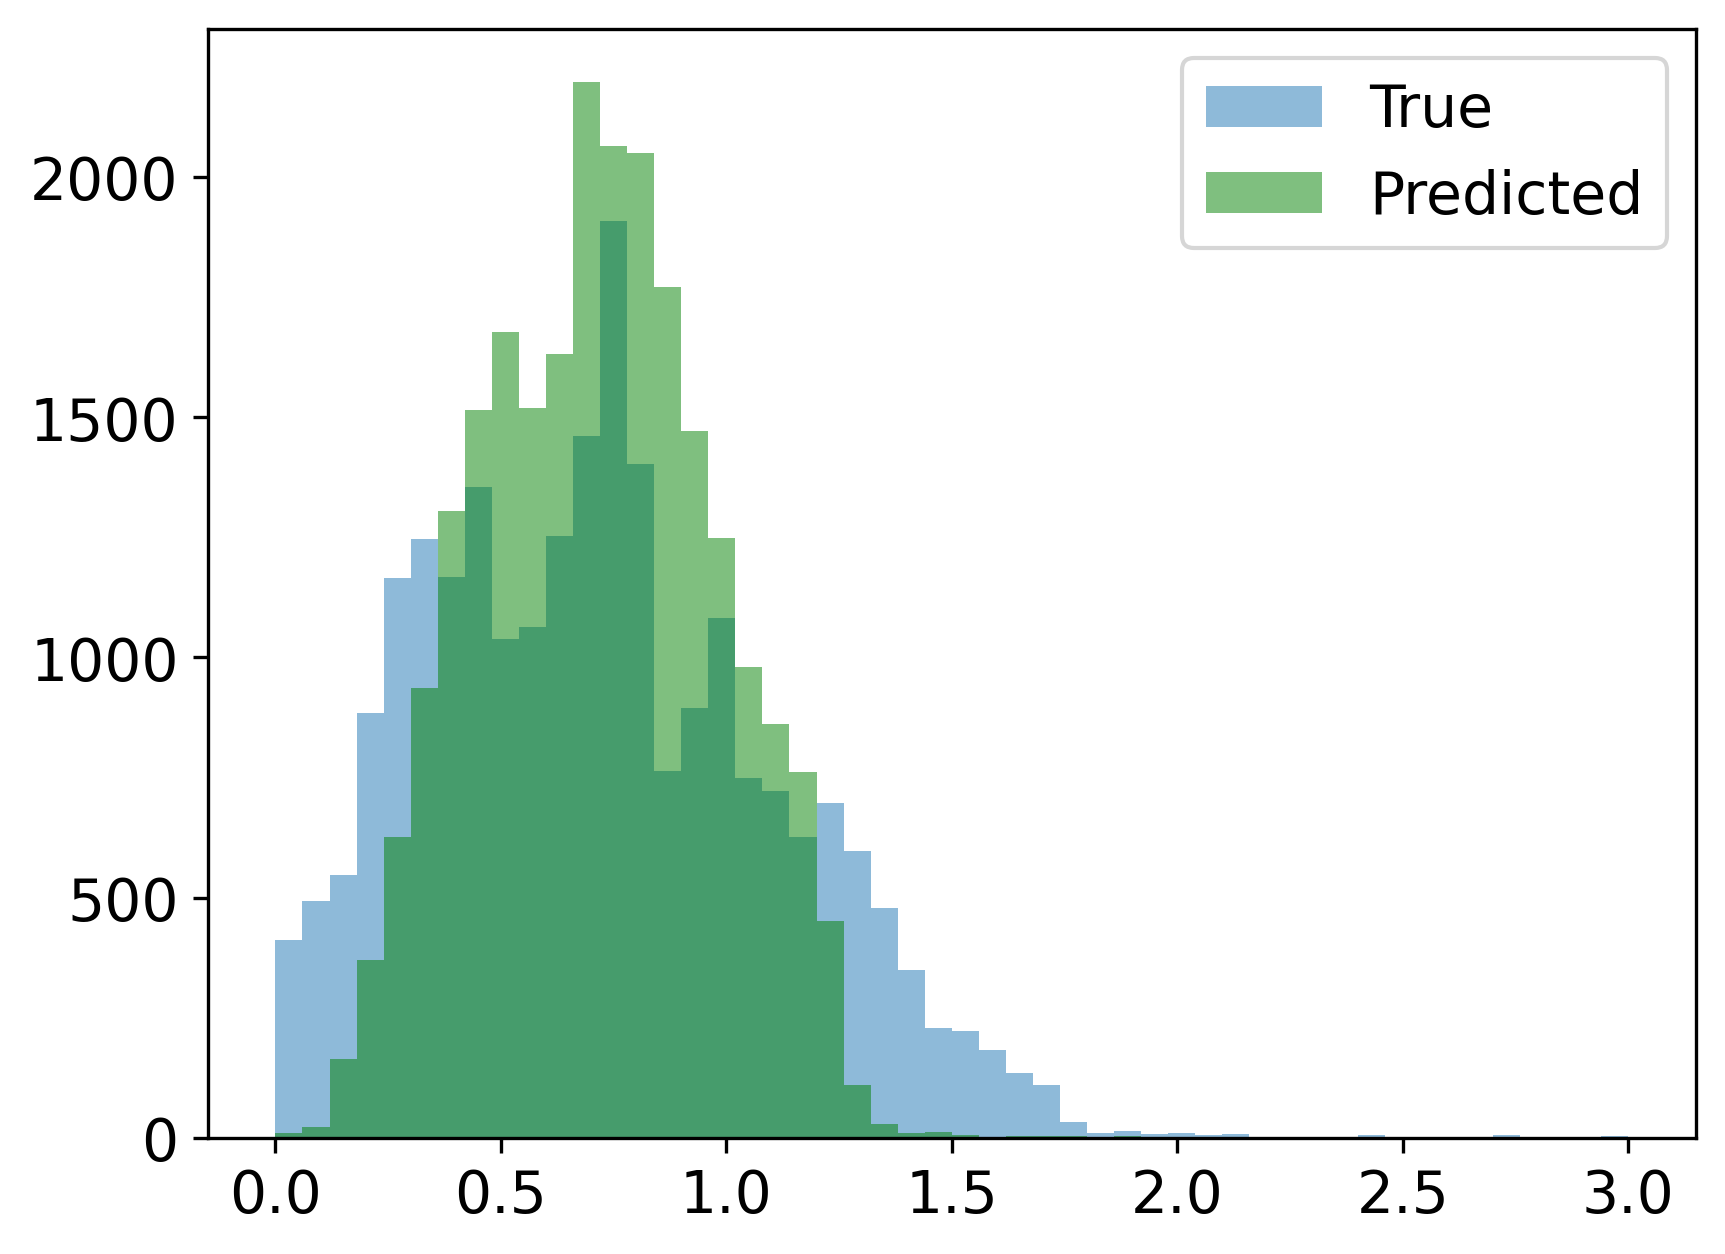

In [28]:
plt.hist(target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

In [29]:
y_phot = cross_val_predict(model, X, y, cv=kf, n_jobs=-1)
y_spec = y.values  # z_spec real

# Calculamos los residuos normalizados
dz_norm = np.abs(y_phot - y_spec) / (1 + y_spec)

# Calculamos la fracción de outliers (eta)
outliers = dz_norm > 0.15
eta = np.mean(outliers) * 100  # En porcentaje

print(f"Outliers (η): {eta:.2f}%")

Outliers (η): 25.59%


y NMAD

In [30]:
# Calculamos sigma_NMAD
mad = np.median(dz_norm)
sigma_nmad = 1.48 * mad

print(f"σ_NMAD : {sigma_nmad:.4f}")


σ_NMAD : 0.0735


**Comparacion:** Nuestra dispersión típica es de $0.0735$, lo que significa que las estimaciones de redshift tienen más de cuatro veces el error/incertidumbre que el modelo del paper. Alrededor de una de cada cuatro galaxias ($25.8\%$) sobrepasa el umbral de error, comparado con solo el $5\%$ del paper. Como vimos con el $R^2$ de prueba ($0.3117$), el Random Forest por defecto memoriza el ruido de entrenamiento en lugar de aprender la física subyacente. Quizás, considerando otras variables y no solo las magnitudes individuales, esto pueda mejorar.

### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [31]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False) #sample sin reemplazo 

In [32]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [34]:
seld = X.loc[sel,:]
selt = target[sel]

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [35]:
littlescores = cross_validate(model,seld,selt, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

In [36]:
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(np.float64(0.27762715338769406), np.float64(0.8763722031531694))

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?



#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [37]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper 

- min_impurity_decrease 

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [ ]:
%%time
import numpy as np
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict
from sklearn.ensemble import RandomForestRegressor

#Toma algunos minutos
param_distributions = {
    'min_impurity_decrease': [0.1, 0.5, 0.0],
    'max_features': [None, 4, 2], 
    'n_estimators': [50, 100, 200],
    'min_samples_split': [10, 20, 100],
    'max_leaf_nodes': [None, 100, 200]
}

# Configuración de RandomizedSearchCV
search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_distributions,
    n_iter=20,          # Prueba 20 combinaciones aleatorias
    cv=kf,              # Usa el KFold anterior
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

search.fit(X, y)

best_model = search.best_estimator_
print("Mejores hiperparámetros encontrados:")
print(search.best_params_)
print(f"Mejor R^2 medio en CV: {search.best_score_:.4f}")

# Evaluación de métricas del paper con el mejor modelo
y_phot_best = cross_val_predict(best_model, X, y, cv=kf, n_jobs=-1)
dz_norm_best = np.abs(y_phot_best - y.values) / (1 + y.values)

sigma_nmad_best = 1.48 * np.median(dz_norm_best)
eta_best = np.mean(dz_norm_best > 0.15) * 100

print(f"\n--- Métricas del Mejor Modelo ---")
print(f"σ_NMAD : {sigma_nmad_best:.4f}  (Paper: 0.0170)")
print(f"Outliers (η): {eta_best:.2f}%     (Paper: 5.00%)")

Mejores hiperparámetros encontrados:
{'n_estimators': 50, 'min_samples_split': 100, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': None, 'max_features': None}
Mejor R^2 medio en CV: 0.3186

--- Métricas del Mejor Modelo ---
σ_NMAD : 0.0964  (Paper: 0.0170)
Outliers (η): 27.32%     (Paper: 5.00%)
CPU times: user 4.65 s, sys: 80.6 ms, total: 4.73 s
Wall time: 1min 12s


Guardamos el resultado en un dataframe y buscamos el mejor modelo 

In [46]:
scores = pd.DataFrame(search.cv_results_)
scoresCV = scores[['params','mean_test_score','std_test_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)


In [49]:
scoresCV

,params,mean_test_score,std_test_score
0,"{'n_estimators': 50, 'min_samples_split': 100, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': N...",0.318602,0.014156
15,"{'n_estimators': 200, 'min_samples_split': 100, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': ...",0.315333,0.012451
4,"{'n_estimators': 100, 'min_samples_split': 20, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 2...",0.299710,0.008674
16,"{'n_estimators': 200, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 2...",0.297852,0.008370
10,"{'n_estimators': 50, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 10...",0.291058,0.012166
19,"{'n_estimators': 100, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 1...",0.289462,0.010687
6,"{'n_estimators': 200, 'min_samples_split': 100, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': ...",0.281101,0.006665
11,"{'n_estimators': 200, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 1...",0.276748,0.006290
13,"{'n_estimators': 200, 'min_samples_split': 100, 'min_impurity_decrease': 0.1, 'max_leaf_nodes': ...",-0.000172,0.000201
12,"{'n_estimators': 200, 'min_samples_split': 10, 'min_impurity_decrease': 0.5, 'max_leaf_nodes': 2...",-0.000172,0.000201


### Mejoran los scores?

**RESPUESTA:** El mejor score de test obtenido en la búsqueda es $R^2 \approx 0.3186$, mientras que el modelo base por defecto consigue un $R^2 \approx 0.3117$. Hay un incremento minúsculo de apenas $\sim 0.007$, lo que muestra que el modelo sigue estando limitado. 


### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [50]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]



In [51]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [52]:
mags.shape

(23822, 9)

In [60]:
#zquality - solo usa objetos con medición de redshift de buena calidad

# Corregimos la compatibilidad de orden de bytes (Big-Endian a Native/Little-Endian)
mags = mags.copy()
for col in mags.columns:
    if mags[col].dtype.byteorder not in ('=', '|', '<'):
        mags[col] = mags[col].values.byteswap().view(mags[col].dtype.newbyteorder('='))

# Filtramos 
mags = mags[mags['zquality'] >= 3]

# Verificamos la nueva forma del DataFrame
print("Dimensiones tras filtrar por zquality >= 3:", mags.shape)
mags.head()

Dimensiones tras filtrar por zquality >= 3: (16857, 9)


,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4
5,23.552186,23.420734,23.010863,22.550723,22.277656,21.860866,1,1,4
6,23.983330,24.104438,23.461145,23.359428,22.929944,22.690175,1,1,4
7,24.665840,24.408938,23.544115,23.155140,22.706477,22.894691,1,1,3


In [61]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data

mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [62]:
mags = mags[mags > -10].dropna()

In [63]:
mags.shape

(6371, 9)

In [64]:
mags = mags[mags < 90].dropna()

In [65]:
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [66]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [67]:
sel_target = target[sel_features.index]

**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.** 

In [ ]:
# Definimos el KFold para el nuevo dataset
kf_new = KFold(n_splits=5, shuffle=True, random_state=42)

# Modelo Benchmark con dataset limpio
scores_new = cross_validate(
    RandomForestRegressor(random_state=42),
    sel_features,
    sel_target,
    cv=kf_new,
    return_train_score=True,
    n_jobs=-1
)

print("=== BENCHMARK (Dataset Limpio - 6307 Objetos) ===")
print(f"R^2 Train promedio: {scores_new['train_score'].mean():.4f} +/- {scores_new['train_score'].std():.4f}")
print(f"R^2 Test promedio:  {scores_new['test_score'].mean():.4f} +/- {scores_new['test_score'].std():.4f}")

# Reoptimización de Hiperparámetros en el dataset limpio
param_distributions = {
    'min_impurity_decrease': [0.1, 0.5, 0.0],
    'max_features': [1.0, 4, 2],
    'n_estimators': [50, 100, 200],
    'min_samples_split': [10, 20, 100],
    'max_leaf_nodes': [None, 100, 200]
}

search_new = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_distributions,
    n_iter=20,
    cv=kf_new,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

search_new.fit(sel_features, sel_target)
best_model_new = search_new.best_estimator_

# Predicciones y Métricas del Paper
y_phot_new = cross_val_predict(best_model_new, sel_features, sel_target, cv=kf_new, n_jobs=-1)
dz_norm_new = np.abs(y_phot_new - sel_target.values) / (1 + sel_target.values)

sigma_nmad_new = 1.48 * np.median(dz_norm_new)
eta_new = np.mean(dz_norm_new > 0.15) * 100

print("\n=== MEJOR MODELO OPTIMIZADO ===")
print(f"Mejores Parámetros: {search_new.best_params_}")
print(f"Mejor R^2 Test (CV): {search_new.best_score_:.4f}")
print(f"σ_NMAD : {sigma_nmad_new:.4f}  (Anterior: 0.0946 | Paper: 0.0170)")
print(f"Outliers (η): {eta_new:.2f}%     (Anterior: ~27%   | Paper: 5.00%)")

=== BENCHMARK (Dataset Limpio - 6307 Objetos) ===
R^2 Train promedio: 0.9629 +/- 0.0026
R^2 Test promedio:  0.7528 +/- 0.0809

=== MEJOR MODELO OPTIMIZADO ===
Mejores Parámetros: {'n_estimators': 200, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 200, 'max_features': 2}
Mejor R^2 Test (CV): 0.7109
σ_NMAD : 0.0568  (Anterior: 0.0735 | Paper: 0.0170)
Outliers (η): 8.56%     (Anterior: ~26%   | Paper: 5.00%)


### Conclusion: Cómo se compara nuestro modelo con el resultado del paper? 

**RESPUESTA:** La reducción de outliers de un $25.80\%$ a solo un $8.56\%$ demuestra que la mayoría de los errores catastróficos del modelo inicial provenían de magnitudes no físicas (como -99 o 99) que distorsionaban las ramificaciones de los árboles, a su vez se acerco al valor del paper (modelo optimizado ($8.56\%$), meta del paper ($5.00\%$)). Aunque la precisión mejoró bastante, nuestra dispersión ($0.0568$) sigue siendo unas $3.3$ veces superior a la del paper ($0.0170$). 

Curiosamente, el modelo Benchmark (Random Forest sin restringir max_leaf_nodes a $200$) logró un $R^2$ levemente mayor ($0.7528$) que el seleccionado por RandomizedSearchCV ($0.7109$). Lo que onfirma que al acotar max_leaf_nodes = 200, la grilla impuso un ligero subajuste, demostrando que para datasets limpios de este tamaño, los árboles requieren una mayor complejidad para resolver regiones complejas de fotometría.

Revise la sección 7 del paper. Podemos mejorar nuestro modelo aún más? Implemente un nuevo modelo con la mejora identificada



En la sección final de discusiones del paper de Zou et al. (2019) (específicamente al analizar cómo mejorar las estimaciones fotométricas respecto a modelos simples de regresión), los autores destacan que las magnitudes individuales en banda ancha varían fuertemente por el brillo total y la distancia de la galaxia. En cambio, los colores (diferencias entre magnitudes de las bandas, u - g o g - i, etc) rastrean la forma del espectro y el desplazamiento de fenómenos reconocibles en el espectro (como la ruptura de Balmer), reduciendo drásticamente la degeneración en el espacio de parámetros.

In [70]:
X_colors = sel_features.copy()

# Creamos los colores fotométricos
bands = ['u', 'g', 'r', 'i', 'z', 'y']
for i in range(len(bands) - 1):
    b1, b2 = bands[i], bands[i+1]
    X_colors[f'{b1}_{b2}'] = X_colors[f'{b1}_apercor'] - X_colors[f'{b2}_apercor']

print(f"Nuevas dimensiones de X con colores: {X_colors.shape}")
print("Nuevas columnas creadas:", [col for col in X_colors.columns if '_' in col and 'apercor' not in col])

# Reentrenamos el Random Forest
kf_new = KFold(n_splits=5, shuffle=True, random_state=42)
model_colors = RandomForestRegressor(n_estimators=200, min_samples_split=10, random_state=42, n_jobs=-1)

# Predicciones y cálculo de métricas
y_phot_colors = cross_val_predict(model_colors, X_colors, sel_target, cv=kf_new, n_jobs=-1)
dz_norm_colors = np.abs(y_phot_colors - sel_target.values) / (1 + sel_target.values)

sigma_nmad_colors = 1.48 * np.median(dz_norm_colors)
eta_colors = np.mean(dz_norm_colors > 0.15) * 100

print("\n=== RENDIMIENTO TRAS APLICAR LA MEJORA DEL PAPER (COLORES) ===")
print(f"σ_NMAD : {sigma_nmad_colors:.4f}  (Sin colores: 0.0568 | Paper: 0.0170)")
print(f"Outliers (η): {eta_colors:.2f}%     (Sin colores: 8.56%  | Paper: 5.00%)")

Nuevas dimensiones de X con colores: (6307, 11)
Nuevas columnas creadas: ['u_g', 'g_r', 'r_i', 'i_z', 'z_y']

=== RENDIMIENTO TRAS APLICAR LA MEJORA DEL PAPER (COLORES) ===
σ_NMAD : 0.0164  (Sin colores: 0.0568 | Paper: 0.0170)
Outliers (η): 3.73%     (Sin colores: 8.56%  | Paper: 5.00%)
